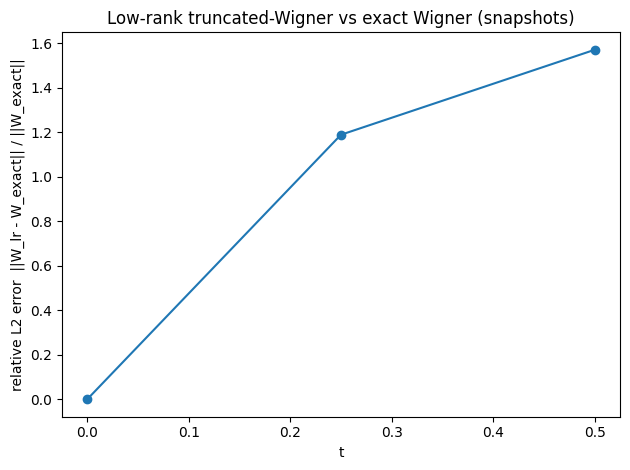

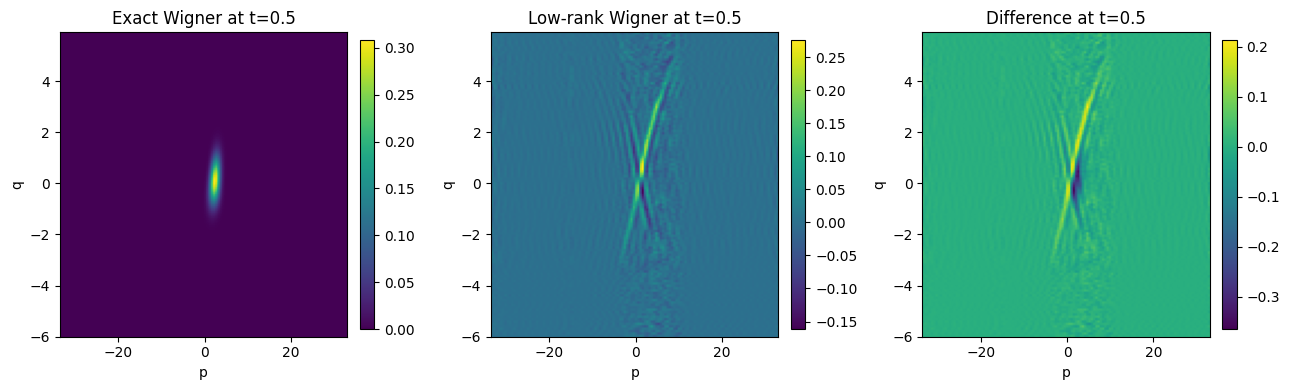

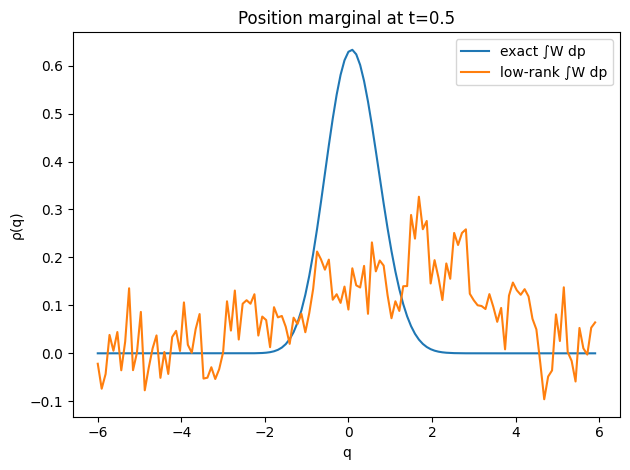

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Compare low-rank Wigner PDE propagation vs "exact" quantum dynamics
# for 1D quartic oscillator V(q)=1/2 m ω^2 q^2 + λ q^4.
#
# Exact dynamics: split-operator (Strang) propagation of ψ(q,t).
# Exact Wigner: computed from ψ via the defining integral using FFT shifts.
#
# Low-rank dynamics: projector-splitting integrator for W ≈ U S V^T (fixed rank r)
# applied to the truncated (O(hbar^2)) Wigner equation:
#   ∂t W = -(p/m) ∂q W + V'(q) ∂p W - (hbar^2/24) V'''(q) ∂p^3 W
#
# Everything uses periodic grids; momentum grid is the FFT-conjugate of the q-grid.
# ============================================================

# -------------------- FFT derivatives & filtering --------------------
def deriv_fft(X, L, order, axis=0):
    n = X.shape[axis]
    dq = L / n
    k = 2.0 * np.pi * np.fft.fftfreq(n, d=dq)  # wave numbers
    shape = [1] * X.ndim
    shape[axis] = n
    ik = (1j * k).reshape(shape)
    Xhat = np.fft.fft(X, axis=axis)
    Yhat = (ik ** order) * Xhat
    return np.fft.ifft(Yhat, axis=axis).real

def lowpass_fft(X, frac=2/3, axis=0):
    n = X.shape[axis]
    f = np.fft.fftfreq(n)
    mask = (np.abs(f) <= 0.5 * frac)
    Xhat = np.fft.fft(X, axis=axis)
    shape = [1] * X.ndim
    shape[axis] = n
    Xhat *= mask.reshape(shape)
    return np.fft.ifft(Xhat, axis=axis).real


# -------------------- Potential and derivatives --------------------
def V_quartic(q, m=1.0, omega=1.0, lam=0.05):
    return 0.5 * m * (omega**2) * q**2 + lam * q**4

def Vprime_quartic(q, m=1.0, omega=1.0, lam=0.05):
    return m * (omega**2) * q + 4.0 * lam * q**3

def Vthird_quartic(q, lam=0.05):
    return 24.0 * lam * q


# -------------------- Low-rank Wigner integrator pieces --------------------
def apply_A0(Y, Lq):      # A0 = -∂q
    return -deriv_fft(Y, L=Lq, order=1, axis=0)

def apply_A0_T(Y, Lq):    # A0^T = +∂q  (since (∂q)^T = -∂q)
    return +deriv_fft(Y, L=Lq, order=1, axis=0)

def apply_A1(Y, Vp_q):    # diag(V')
    return Vp_q[:, None] * Y

def apply_A2(Y, V3_q, hbar):  # -(hbar^2/24) diag(V''')
    return -(hbar**2 / 24.0) * (V3_q[:, None] * Y)

def apply_B0(V, p, m):        # diag(p/m)
    return (p / m)[:, None] * V

def apply_B1(V, Lp):          # ∂p
    return deriv_fft(V, L=Lp, order=1, axis=0)

def apply_B2(V, Lp):          # ∂p^3
    return deriv_fft(V, L=Lp, order=3, axis=0)

def apply_B0_T(X, p, m):
    return (p / m)[:, None] * X

def apply_B1_T(X, Lp):        # (∂p)^T = -∂p
    return -deriv_fft(X, L=Lp, order=1, axis=0)

def apply_B2_T(X, Lp):        # (∂p^3)^T = -∂p^3
    return -deriv_fft(X, L=Lp, order=3, axis=0)

def rk4(Y, dt, f):
    k1 = f(Y)
    k2 = f(Y + 0.5*dt*k1)
    k3 = f(Y + 0.5*dt*k2)
    k4 = f(Y + dt*k3)
    return Y + (dt/6.0)*(k1 + 2*k2 + 2*k3 + k4)

def mass_from_factors(U, S, V, dq, dp):
    ones_q = np.ones(U.shape[0])
    ones_p = np.ones(V.shape[0])
    a = U.T @ ones_q
    b = V.T @ ones_p
    return (a @ S @ b) * dq * dp

def rescale_mass(U, S, V, dq, dp, target_mass=1.0):
    mcur = mass_from_factors(U, S, V, dq, dp)
    if not np.isfinite(mcur) or abs(mcur) < 1e-300:
        return U, S, V
    S = S * (target_mass / mcur)
    return U, S, V

def low_rank_step(
    U, S, V, dt, q, p, Lq, Lp, dq, dp,
    m=1.0, hbar=1.0, omega=1.0, lam=0.05,
    filter_frac=2/3, filter_V=True, filter_U=False,
    fix_mass=True
):
    Vp_q = Vprime_quartic(q, m=m, omega=omega, lam=lam)
    V3_q = Vthird_quartic(q, lam=lam)

    # Mk = V^T (Bk V)
    B0V = apply_B0(V, p, m)
    B1V = apply_B1(V, Lp)
    B2V = apply_B2(V, Lp)
    M0 = V.T @ B0V
    M1 = V.T @ B1V
    M2 = V.T @ B2V

    # (1) K-step: K = U S, V fixed
    K = U @ S

    def Kdot(Kmat):
        return (apply_A0(Kmat @ M0, Lq)
              + apply_A1(Kmat @ M1, Vp_q)
              + apply_A2(Kmat @ M2, V3_q, hbar))

    K = rk4(K, dt, Kdot)
    U, R = np.linalg.qr(K, mode="reduced")
    S = R

    # (2) S-step
    A0U = apply_A0(U, Lq)
    A1U = apply_A1(U, Vp_q)
    A2U = apply_A2(U, V3_q, hbar)
    Ahat0 = U.T @ A0U
    Ahat1 = U.T @ A1U
    Ahat2 = U.T @ A2U

    def Sdot(Smat):
        return (Ahat0 @ Smat @ M0) + (Ahat1 @ Smat @ M1) + (Ahat2 @ Smat @ M2)

    S = rk4(S, dt, Sdot)

    # (3) L-step: L = V S^T, U fixed
    L = V @ S.T
    N0 = U.T @ apply_A0_T(U, Lq)
    N1 = U.T @ A1U
    N2 = U.T @ A2U

    def Ldot(Lmat):
        return (apply_B0_T(Lmat @ N0, p, m)
              + apply_B1_T(Lmat @ N1, Lp)
              + apply_B2_T(Lmat @ N2, Lp))

    L = rk4(L, dt, Ldot)
    V, R = np.linalg.qr(L, mode="reduced")
    S = R.T

    # mild filtering (important for stability in the ∂p^3 term)
    if filter_V:
        Vf = lowpass_fft(V, frac=filter_frac, axis=0)
        V, Rv = np.linalg.qr(Vf, mode="reduced")
        S = S @ Rv.T

    if filter_U:
        Uf = lowpass_fft(U, frac=filter_frac, axis=0)
        U, Ru = np.linalg.qr(Uf, mode="reduced")
        S = Ru @ S

    if fix_mass:
        U, S, V = rescale_mass(U, S, V, dq, dp, target_mass=1.0)

    return U, S, V


# -------------------- Exact quantum propagation (split-operator) --------------------
def gaussian_psi(q, q0=0.0, p0=0.0, sigma=0.8, hbar=1.0):
    # ψ(q) ∝ exp(-(q-q0)^2/(2σ^2) + i p0 (q-q0)/ħ)
    psi = np.exp(-0.5*((q-q0)/sigma)**2 + 1j*(p0*(q-q0)/hbar))
    return psi

def normalize_psi(psi, dq):
    nrm = np.sqrt(np.sum(np.abs(psi)**2) * dq)
    return psi / nrm

def split_operator_step(psi, dt, Vq, p, m=1.0, hbar=1.0):
    psi = psi * np.exp(-1j * Vq * (dt/(2*hbar)))
    psi_k = np.fft.fft(psi)
    psi_k = psi_k * np.exp(-1j * (p**2/(2*m)) * (dt/hbar))
    psi = np.fft.ifft(psi_k)
    psi = psi * np.exp(-1j * Vq * (dt/(2*hbar)))
    return psi


# -------------------- Exact Wigner from ψ (periodic, FFT shifts) --------------------
def wigner_from_psi(psi, Lq, hbar=1.0):
    """
    Computes W(q_i,p_j) on the same q-grid and FFT-conjugate p-grid.
    Uses definition: W(q,p) = (1/2πħ) ∫ dy e^{-i p y/ħ} ψ*(q-y/2) ψ(q+y/2).
    Fractional shifts are computed exactly (periodic band-limited) via Fourier phases.
    """
    N = psi.size
    dq = Lq / N
    k = 2.0*np.pi*np.fft.fftfreq(N, d=dq)
    p = hbar * k  # FFT momentum grid (standard ordering)

    psi_hat = np.fft.fft(psi)

    n = np.arange(-N//2, N//2)       # y index (centered)
    y = n * dq
    g = np.empty((N, N), dtype=np.complex128)  # g(q_i, y_n)

    for col, yy in enumerate(y):
        s = 0.5 * yy
        phase = np.exp(1j * k * s)
        psi_plus  = np.fft.ifft(psi_hat * phase)
        psi_minus = np.fft.ifft(psi_hat * np.conj(phase))
        g[:, col] = np.conj(psi_minus) * psi_plus

    g_std = np.fft.ifftshift(g, axes=1)  # put y in standard FFT order
    W_std = (dq / (2*np.pi*hbar)) * np.fft.fft(g_std, axis=1)
    W = W_std.real
    return W, p


# -------------------- Diagnostics --------------------
def rel_l2(A, B, dq, dp):
    num = np.sqrt(np.sum((A-B)**2) * dq * dp)
    den = np.sqrt(np.sum(B**2) * dq * dp)
    return num / (den + 1e-300)

def marg_q(W, dp):
    return np.sum(W, axis=1) * dp

def plot_wigner(ax, W, q, p, title):
    # show in (q,p) with p shifted for readability
    pS = np.fft.fftshift(p)
    WS = np.fft.fftshift(W, axes=1)
    im = ax.imshow(WS, aspect="auto",
                   extent=[pS[0], pS[-1], q[0], q[-1]],
                   origin="lower")
    ax.set_title(title)
    ax.set_xlabel("p")
    ax.set_ylabel("q")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)


# ============================================================
# Main run
# ============================================================
def run_compare(
    N=128,              # grid size in q (and p)
    Lq=12.0,            # q-domain length
    r=20,               # low-rank (bond dimension)
    T=0.5,              # final time
    dt=2e-4,            # time step (reduce if needed)
    m=1.0, hbar=1.0,
    omega=1.0, lam=0.05,
    q0=-1.0, p0=2.0, sigma=0.8,
    snapshot_times=(0.0, 0.25, 0.5),
    filter_frac=2/3
):
    dq = Lq / N
    q = (np.arange(N) - N//2) * dq  # centered periodic grid

    # FFT momentum grid for this q grid
    k = 2.0*np.pi*np.fft.fftfreq(N, d=dq)
    p = hbar * k
    dp = (2*np.pi*hbar) / Lq
    Lp = N * dp

    Vq = V_quartic(q, m=m, omega=omega, lam=lam)

    # exact initial psi and its Wigner
    psi = normalize_psi(gaussian_psi(q, q0=q0, p0=p0, sigma=sigma, hbar=hbar), dq)
    W_exact0, _ = wigner_from_psi(psi, Lq, hbar=hbar)

    # low-rank init from W_exact0
    U0, s0, Vt0 = np.linalg.svd(W_exact0, full_matrices=False)
    U = U0[:, :r]
    S = np.diag(s0[:r])
    V = Vt0[:r, :].T

    # orthonormalize U,V and absorb into S
    U, Ru = np.linalg.qr(U, mode="reduced")
    V, Rv = np.linalg.qr(V, mode="reduced")
    S = Ru @ S @ Rv.T
    U, S, V = rescale_mass(U, S, V, dq, dp, target_mass=1.0)

    # time loop
    nsteps = int(np.round(T / dt))
    times = np.linspace(0.0, T, nsteps+1)

    snap_set = set([float(t) for t in snapshot_times])
    snap_idx = {int(np.round(t/dt)): t for t in snapshot_times}
    snaps = {}

    # store t=0
    snaps[0.0] = {
        "W_exact": W_exact0,
        "W_lr": (U @ S @ V.T),
        "psi": psi
    }

    for n in range(1, nsteps+1):
        # exact step
        psi = split_operator_step(psi, dt, Vq, p, m=m, hbar=hbar)
        psi = normalize_psi(psi, dq)

        # low-rank step
        U, S, V = low_rank_step(
            U, S, V, dt, q, p, Lq, Lp, dq, dp,
            m=m, hbar=hbar, omega=omega, lam=lam,
            filter_frac=filter_frac, filter_V=True, filter_U=False,
            fix_mass=True
        )

        if n in snap_idx:
            t = snap_idx[n]
            W_exact, _ = wigner_from_psi(psi, Lq, hbar=hbar)
            W_lr = U @ S @ V.T
            snaps[t] = {"W_exact": W_exact, "W_lr": W_lr, "psi": psi}

    # compute summary errors at snapshots
    summary = []
    for t in sorted(snaps.keys()):
        Wex = snaps[t]["W_exact"]
        Wlr = snaps[t]["W_lr"]
        e = rel_l2(Wlr, Wex, dq, dp)
        summary.append((t, e))

    return q, p, dq, dp, snaps, np.array(summary)


# -------------------- Run and plot --------------------
if __name__ == "__main__":
    q, p, dq, dp, snaps, summary = run_compare(
        N=128, Lq=12.0, r=20, T=0.5, dt=2e-4,
        omega=1.0, lam=0.05, q0=-1.0, p0=2.0, sigma=0.8,
        snapshot_times=(0.0, 0.25, 0.5),
        filter_frac=2/3
    )

    # error vs time (snapshots)
    plt.figure()
    plt.plot(summary[:, 0], summary[:, 1], marker="o")
    plt.xlabel("t")
    plt.ylabel("relative L2 error  ||W_lr - W_exact|| / ||W_exact||")
    plt.title("Low-rank truncated-Wigner vs exact Wigner (snapshots)")
    plt.tight_layout()

    # Wigner heatmaps at final snapshot
    t_show = float(summary[-1, 0])
    Wex = snaps[t_show]["W_exact"]
    Wlr = snaps[t_show]["W_lr"]
    Wdiff = Wlr - Wex

    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    plot_wigner(axes[0], Wex, q, p, f"Exact Wigner at t={t_show}")
    plot_wigner(axes[1], Wlr, q, p, f"Low-rank Wigner at t={t_show}")
    plot_wigner(axes[2], Wdiff, q, p, f"Difference at t={t_show}")
    plt.tight_layout()

    # Compare q-marginals at final snapshot
    rhoq_ex = marg_q(Wex, dp)
    rhoq_lr = marg_q(Wlr, dp)

    plt.figure()
    plt.plot(q, rhoq_ex, label="exact ∫W dp")
    plt.plot(q, rhoq_lr, label="low-rank ∫W dp")
    plt.xlabel("q")
    plt.ylabel("ρ(q)")
    plt.title(f"Position marginal at t={t_show}")
    plt.legend()
    plt.tight_layout()

    plt.show()

    